In [3]:
import networkx as nx
import pandas as pd
import os

os.chdir('/..')
os.chdir('Users/alexp/OneDrive - University of New Brunswick/Grad Studies/Modelling_transport_pathways/Clean_data_sets')

In [4]:
gravity_df=pd.read_csv('Gravity_calc.csv',index_col=0)
gravity_df.head(3)

,Bedford,Edmunston,Fredericton,Moncton,Oromocto
ADDA Fundy Tides CG- City,62865.588631,811.384344,6455.652199,17145.750546,1072.447980
Adventures East Campground & Cottages,102992.239639,1349.646820,8909.002740,15806.950948,1449.555988
All Done Camping,59120.357286,1575.415614,22092.343559,52581.515837,3982.233818


In [5]:
#reshape the dataframe so that the columns origin city is in it's own row(the reset index is to add the campground to every row needed) to use as a network x model
Gravity_df_stack = gravity_df.stack().reset_index().rename(columns={'level_0':'Campground','level_1' : 'Origin', 0 :'Relative_introduction_probability'}, errors='raise')
Gravity_df_stack.head(3)

,Campground,Origin,Relative_introduction_probability
0,ADDA Fundy Tides CG- City,Bedford,62865.588631
1,ADDA Fundy Tides CG- City,Edmunston,811.384344
2,ADDA Fundy Tides CG- City,Fredericton,6455.652199


ImportError: requires pygraphviz http://pygraphviz.github.io/

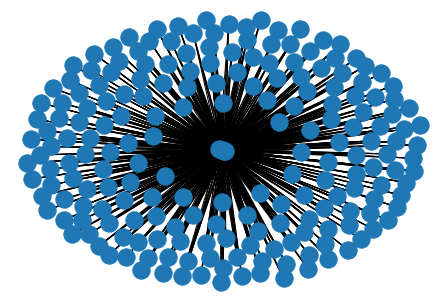

In [89]:
import matplotlib.pyplot as plt
Introduction_network=nx.from_pandas_edgelist(Gravity_df_stack,source='Origin',target='Campground')
nx.draw(Introduction_network)
nx.write_edgelist(Introduction_network,path='campground_edgelist.gz')
A = nx.nx_agraph.to_agraph(Introduction_network)  # convert to a graphviz graph
A.layout()  # neato layout
A.draw("k5.ps")  # write postscript in k5.ps with neato layou


In [76]:
#Importing the initial states of the nodes where Edmunston, Fredericton, Moncton,Bedford, and Oromocto already have an initial infection

def initial_state(G):
    state = {}

    for node in G.nodes:
        if any(x in node for x in ['Edmunston', 'Fredericton','Moncton','Bedford']):
            state[node] = 'infected'
        elif node == 'Oromocto':
            state[node] = 'infected'
        else:
            state[node] = 'not infected'
    return state

In [77]:
initial_state(Introduction_network)

{'Bedford': 'infected',
 'ADDA Fundy Tides CG- City': 'not infected',
 'Edmunston': 'infected',
 'Fredericton': 'infected',
 'Moncton': 'infected',
 'Oromocto': 'infected',
 'Adventures East Campground & Cottages': 'not infected',
 'All Done Camping': 'not infected',
 'All Points East Campground': 'not infected',
 'Amherst Shore Provincial Park': 'not infected',
 'Anchorage Provincial Park': 'not infected',
 'Armstrong Brook-Mount Carleton Provincial Park': 'not infected',
 'Baddeck Cabot Trail Campground': 'not infected',
 'Battery Provincial Park': 'not infected',
 'Bear Falls Wilderness Campground': 'not infected',
 'BeechBrook Campground': 'not infected',
 'Belle Baie Park': 'not infected',
 'Ben Eoine Beach RV Resort & Campground': 'not infected',
 "Ben's Lake Campground & Chalet": 'not infected',
 'Big Intervale-Cape Breton Highlands National Park': 'not infected',
 'Birchwood Campground & Cottages': 'not infected',
 'Blomidon Provincial Park': 'not infected',
 'Blue Heron Town P

In [78]:
import random

P_AWAKEN = 0.2
def state_transition(G, current_state):
    next_state = {}
    for node in G.nodes:
        if current_state[node] == 'not infected':
            if random.random() < P_AWAKEN:
                next_state[node] = 'infected'
    return next_state

In [79]:
test_state = initial_state(Introduction_network)
state_transition(Introduction_network, test_state)

{'Belle Baie Park': 'infected',
 "Ben's Lake Campground & Chalet": 'infected',
 'Birchwood Campground & Cottages': 'infected',
 'Borden / Summerside KOA': 'infected',
 'Boylston Provincial Park': 'infected',
 'Cabot Beach Provincial Park': 'infected',
 "Camper's City RV Resort": 'infected',
 'Camping Beausejour': 'infected',
 'Camping Colibri sur Mer+Motel et Camping Colibri': 'infected',
 'Camping Murraywood Park': 'infected',
 'Cavendish Sunset Campground': 'infected',
 'Cavendish-Prince Edward Island National Park': 'infected',
 'Century Farm Family Campground': 'infected',
 'Cornwall / Charlottetown KOA': 'infected',
 'Cote-a-Fabien- Kouchibouguac National Park': 'infected',
 'Cymbria Campground': 'infected',
 'Dunromin Campsite and Cabins': 'infected',
 'E&F Webber Lakeside Park Ltd': 'infected',
 'Elm River RV Park': 'infected',
 'Fishermans Cove RV & Campground': 'infected',
 'Great Bear Camping': 'infected',
 'Ile Lameque Municipal Park': 'infected',
 'Ingonish Beach-Cape Breto

In [53]:
from simulation import Simulation

sim = Simulation(Introduction_network, initial_state, state_transition, name='Simple Sim')

In [60]:
for node in Introduction_network: 
    if test_state[node] == 'infected':
        print (node)

Bedford
Edmunston
Fredericton
Moncton
Oromocto
Sunbury-Oromocto Park


In [81]:
sim.run()

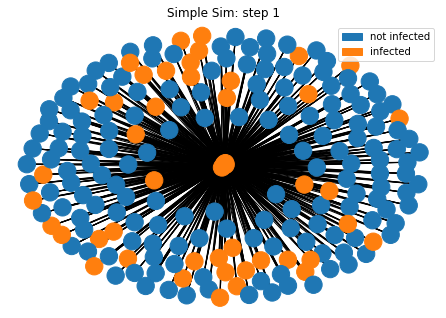

In [83]:
sim.draw()

In [84]:
sim.run(3)

In [86]:
sim.steps

4

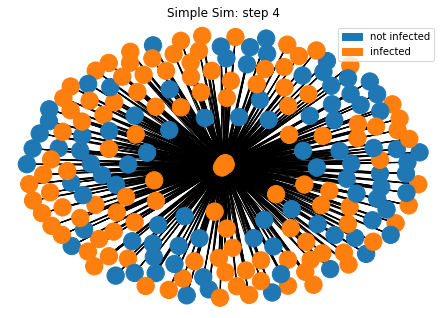

In [87]:
sim.draw()